# Practical tasks

##### Please explore the datasets and answer the questions below.
##### Here are some guidlines and advices you should consider:
* you can add as many cells as is comfortable for you for each answer
* some questions require your explanation. Add a cell and choose a markdown option in the menu 
* when you are making plots, please add labels to the axes

In [149]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import seaborn as sns
from sklearn.cluster import KMeans
# you will need to import more libraries as needed

from sklearn.datasets import make_blobs
import scipy.cluster.hierarchy as shc
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import DBSCAN
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report


# Clustering tasks

The problem that we are going to solve in this section is to segment customers into different groups based on their shopping trends.

The dataset for this problem `shopping-data.csv`

#### 1. Load the data and preview

In [150]:
customer_data = pd.read_csv('shopping-data.csv')

In [151]:
customer_data.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [152]:
customer_data.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


#### 2. Plot scatter plot for annual income and spending score which will be used for clustering in the next steps

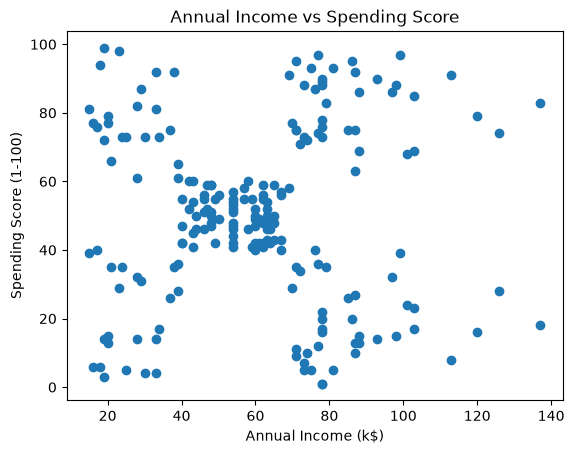

In [153]:
plt.scatter(customer_data["Annual Income (k$)"], customer_data["Spending Score (1-100)"])
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Annual Income vs Spending Score")
plt.show()

#### 3. Normalize the data

In [154]:
X = customer_data[["Annual Income (k$)", "Spending Score (1-100)"]]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])


[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


#### 4. Use Elbow method to decide number of clusters

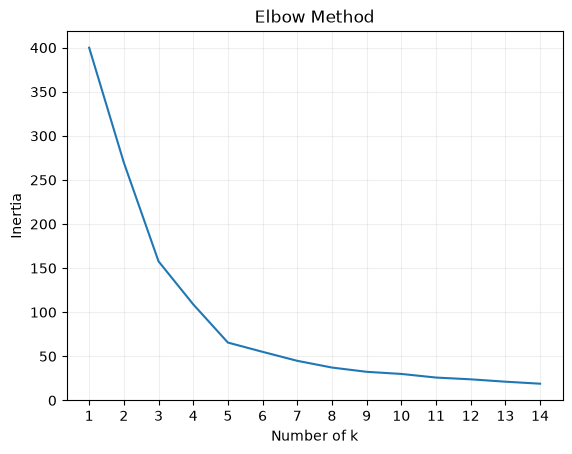

In [155]:
elbow = []
for i in range(1,15):
    kmeans = KMeans(n_clusters=i, init="k-means++", random_state=42, max_iter=300, n_init=10)
    kmeans.fit(X_scaled)
    elbow.append(kmeans.inertia_)

plt.plot(range(1,15), elbow)
plt.xticks(range(1,15))
plt.xlabel("Number of k")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.grid(True, alpha=0.2)
plt.show()

#### 5. Perform Clustering using KMeans

In [156]:
kmeans = KMeans(n_clusters=5, init="k-means++", random_state=42, max_iter=300, n_init=10)
y_kmeans = kmeans.fit_predict(X_scaled)

print(y_kmeans)

[4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4
 2 4 2 4 2 4 0 4 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 1 3 1 0 1 3 1 3 1 0 1 3 1 3 1 3 1 3 1 0 1 3 1 3 1
 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3
 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1]


#### 6. Plot scatter plot and color code in clustered groups

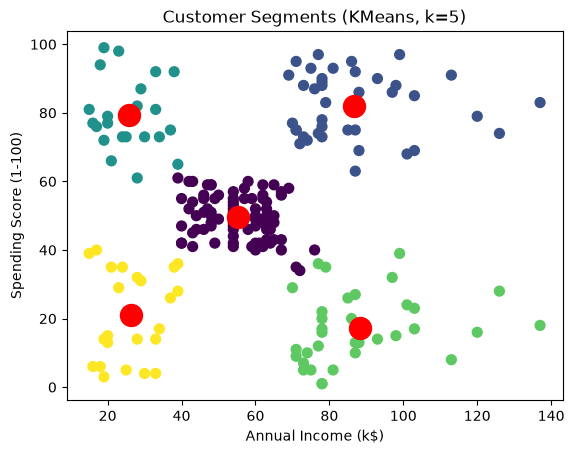

In [157]:
plt.scatter(X["Annual Income (k$)"], X["Spending Score (1-100)"], c=y_kmeans, cmap="viridis", s=50)

centers = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(centers[:, 0], centers[:, 1], c="red", s=250)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Customer Segments (KMeans, k=5)")
plt.show()

#### 7. Plot dendrogram to decide number of clusters for Hierarchical Clustering. <br> Explain (free text in a markdown cell) what is the optimal number of clusters and why

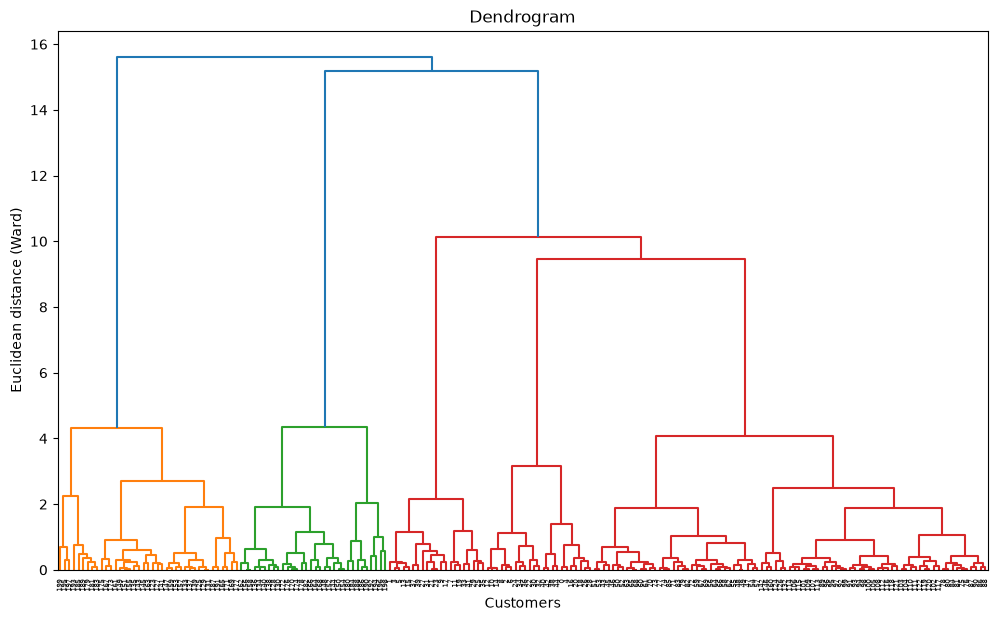

In [158]:
plt.figure(figsize=(12, 7))
dend = shc.dendrogram(shc.linkage(X_scaled, method="ward"))
plt.title("Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Euclidean distance (Ward)")
plt.show()

Optimal count is 5. On the horizontal line above that the clusters are far apart and would group suboptimally. This also matches elbow method prediction.

#### 8. Do clustering using Hierarchical Clustering

In [159]:
hc = AgglomerativeClustering(n_clusters=5, metric="euclidean", linkage="ward")
y_hc = hc.fit_predict(X_scaled)

#### 9. Plot scatter plot and color code in clustered groups

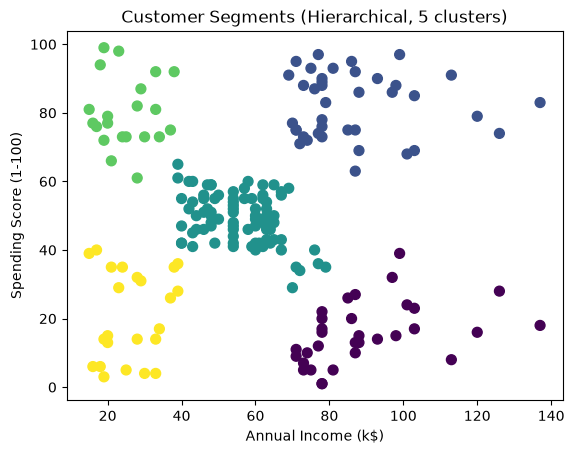

In [160]:
plt.scatter(X["Annual Income (k$)"], X["Spending Score (1-100)"], c=y_hc, cmap="viridis", s=50)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Customer Segments (Hierarchical, 5 clusters)")
plt.show()

####  10. Do KMeans and DBSCAN clustering on this data

In [161]:
moons_X, moon_y = make_moons(n_samples=2000, random_state=42)

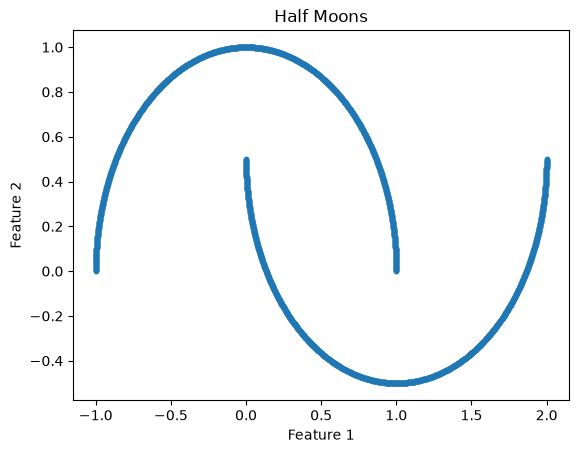

In [162]:
plt.scatter(moons_X[:, 0], moons_X[:, 1], s=10)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Half Moons")
plt.show()

#### Using KMeans (do clustering and plot results (each cluster in own color))

In [163]:
kmeans_moons = KMeans(n_clusters=2, random_state=42, n_init=10)
y_moons_km = kmeans_moons.fit_predict(moons_X)

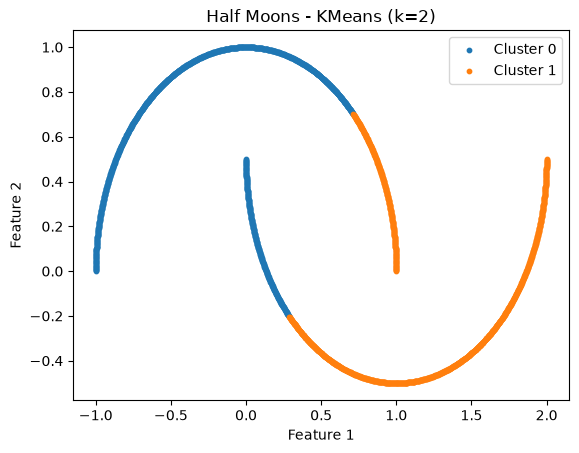

In [164]:
for i in range(2):
    plt.scatter(moons_X[y_moons_km == i, 0], moons_X[y_moons_km == i, 1], s=10, label=f"Cluster {i}")

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Half Moons - KMeans (k=2)")
plt.legend()
plt.show()

#### 11. Using DBSCAN do clustering and plot results (each cluster in own color). Find the most suitable eps and minimal samples number

In [165]:
for eps in [0.005, 0.01, 0.05, 0.1, 0.3, 0.5, 0.6, 1.0]:
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(moons_X)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)
    print(f"eps={eps}: {n_clusters} clusters, {n_noise} noise points")

eps=0.005: 0 clusters, 2000 noise points
eps=0.01: 2 clusters, 0 noise points
eps=0.05: 2 clusters, 0 noise points
eps=0.1: 2 clusters, 0 noise points
eps=0.3: 2 clusters, 0 noise points
eps=0.5: 2 clusters, 0 noise points
eps=0.6: 1 clusters, 0 noise points
eps=1.0: 1 clusters, 0 noise points


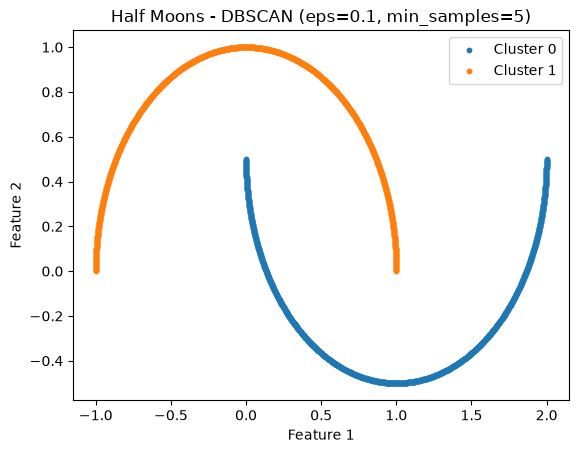

In [166]:
dbscan = DBSCAN(eps=0.1, min_samples=5)
y_moons_db = dbscan.fit_predict(moons_X)

for label in np.unique(y_moons_db):
    name = "Noise" if label == -1 else f"Cluster {label}"
    plt.scatter(moons_X[y_moons_db == label, 0], moons_X[y_moons_db == label, 1], s=10, label=name)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Half Moons - DBSCAN (eps=0.1, min_samples=5)")
plt.legend()
plt.show()

#### 12. Compare the results of K-means and DBSCAN clustering
Explain why one or another is prefferable for such dataset, and differences if any.

### Perform PCA on penguins :)
###### This section uses kaggle dataset (https://www.kaggle.com/datasets/youssefaboelwafa/clustering-penguins-species/data)
###### The tasks below include data analysis, data preprocessing, PCA, and application of classification to predict the target

#### 13. Describe the data. Do any additional exporations as you feel

In [167]:
# Dataset
penguins = pd.read_csv('penguins.csv')
penguins.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE


In [168]:
print("Shape:", penguins.shape)
penguins.info()
print(penguins.replace(".", np.nan).isna().sum())
penguins.describe()

Shape: (344, 5)
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   culmen_length_mm   342 non-null    float64
 1   culmen_depth_mm    342 non-null    float64
 2   flipper_length_mm  342 non-null    float64
 3   body_mass_g        342 non-null    float64
 4   sex                335 non-null    str    
dtypes: float64(4), str(1)
memory usage: 13.6 KB
culmen_length_mm      2
culmen_depth_mm       2
flipper_length_mm     2
body_mass_g           2
sex                  10
dtype: int64


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,214.014620,4201.754386
std,5.459584,1.974793,260.558057,801.954536
min,32.100000,13.100000,-132.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.750000,4750.000000
max,59.600000,21.500000,5000.000000,6300.000000


#### Based on dataframe describe, in own words explain any abnormal characteristics 

flipper_length_mm has abnormal values. Lowest value is -132 and length of something cannot be in negatives, additionally max value is 5000 which is also abnormal compared to average and mean. Other values seem to be within range of "normal".

#### 14. Explore corrupted data

In [169]:
missing = penguins[penguins.replace(".", np.nan).isna().any(axis=1)]
print(missing)
print("Shape:", missing.shape)

     culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g  sex
3                 NaN              NaN                NaN          NaN  NaN
8                34.1             18.1              193.0       3475.0  NaN
10               37.8             17.1              186.0       3300.0  NaN
11               37.8             17.3              180.0       3700.0  NaN
47               37.5             18.9              179.0       2975.0  NaN
246              44.5             14.3              216.0       4100.0  NaN
286              46.2             14.4              214.0       4650.0  NaN
324              47.3             13.8              216.0       4725.0  NaN
336              44.5             15.7              217.0       4875.0    .
339               NaN              NaN                NaN          NaN  NaN
Shape: (10, 5)


In [170]:
print(penguins["sex"].value_counts(dropna=False))

sex
MALE      169
FEMALE    165
NaN         9
.           1
Name: count, dtype: int64


In [171]:
anomal = penguins[(penguins["flipper_length_mm"] < 0) | (penguins["flipper_length_mm"] > 300)]
print(anomal)

    culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g   sex
9               42.0             20.2             5000.0       4250.0  MALE
14              34.6             21.1             -132.0       4400.0  MALE


#### 15. Based on observations above, prepare the data for PCA. Only valid rows should be present. <br> Preview dataframe, show its size

In [172]:
num_cols = ["culmen_length_mm", "culmen_depth_mm", "flipper_length_mm", "body_mass_g"]

penguins_clean = penguins.dropna()
penguins_clean = penguins_clean[penguins_clean["sex"].isin(["MALE", "FEMALE"])]
penguins_clean = penguins_clean[(penguins_clean["flipper_length_mm"] > 0) &
                                (penguins_clean["flipper_length_mm"] < 300)]

print(penguins_clean.shape)
penguins_clean.head()

(332, 5)


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
4,36.7,19.3,193.0,3450.0,FEMALE
5,39.3,20.6,190.0,3650.0,MALE


In [173]:
scaler_p = StandardScaler()
X_penguins = scaler_p.fit_transform(penguins_clean[num_cols])

In [174]:
y_penguins = penguins_clean["sex"]

#### 15. Explain the chosen null values handling strategy, how it affects the dataset (pros/cons)

I removed all invalid rows, missing values, row value with sex ".", impossible values for flipper lengths. This was 12 rows so about 3.5% of all data.

This was simple and fast but we did lose 3.5% of already not very large data set. Alternativelly we would have to replace the missing values with mean values from dataset but I believe dropping theese values would give more accurate data.


#### 16. Perform PCA with 2 components. Plot the results 

Explained variance: [0.68713344 0.19641564]
Total: 0.8835490785942348


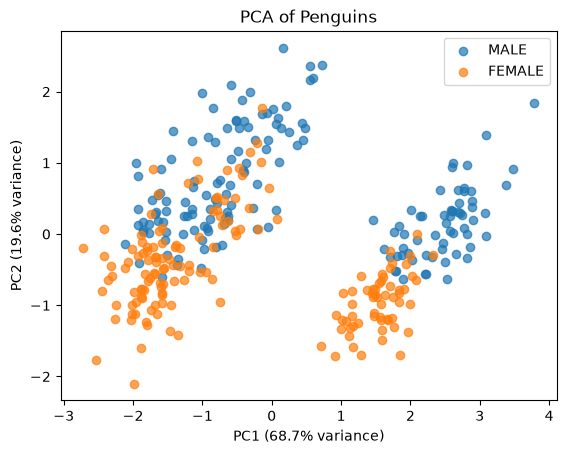

In [175]:
pca = PCA(n_components=2)
X_penguins_pca = pca.fit_transform(X_penguins)

print("Explained variance:", pca.explained_variance_ratio_)
print("Total:", pca.explained_variance_ratio_.sum())

colors = {"MALE": "tab:blue", "FEMALE": "tab:orange"}
for sex, color in colors.items():
    mask = (y_penguins == sex).values
    plt.scatter(X_penguins_pca[mask, 0], X_penguins_pca[mask, 1], c=color, label=sex, alpha=0.7)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.title("PCA of Penguins")
plt.legend()
plt.show()

#### 17. Display scree plots to determine the optimal number of components and cumulative explained variance

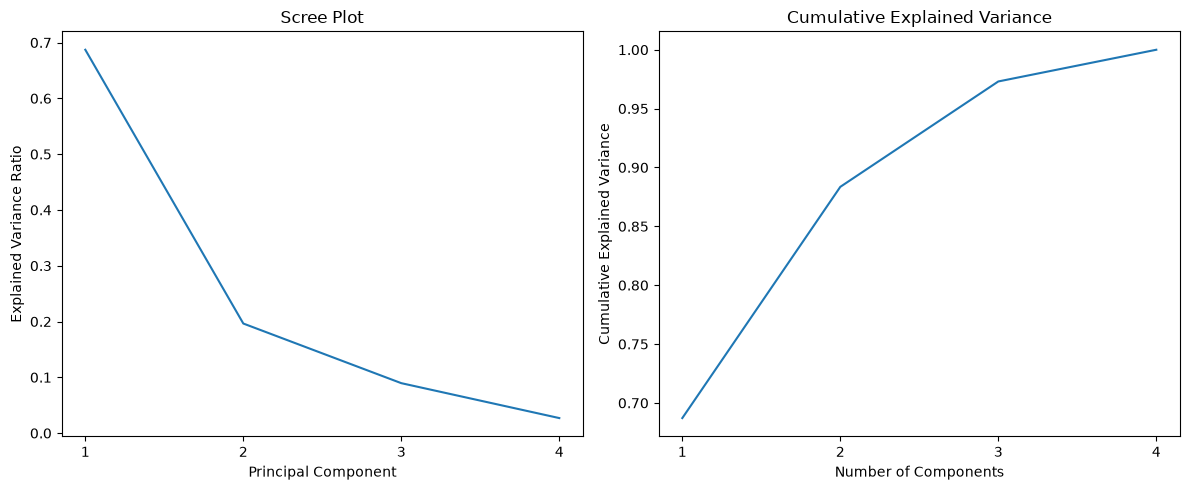

In [176]:
pca_full = PCA()
pca_full.fit(X_penguins)
n = range(1, len(pca_full.explained_variance_ratio_) + 1)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(n, pca_full.explained_variance_ratio_)
plt.xticks(n)
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("Scree Plot")

plt.subplot(1, 2, 2)
plt.plot(n, np.cumsum(pca_full.explained_variance_ratio_))
plt.xticks(n)
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance")

plt.tight_layout()
plt.show()

#### 18. Calculate (show in numbers) and display component loadings

In [177]:
loadings = pd.DataFrame(pca.components_.T, columns=["PC1", "PC2"], index=num_cols)
print(loadings)

                        PC1       PC2
culmen_length_mm   0.453174  0.604990
culmen_depth_mm   -0.398518  0.792959
flipper_length_mm  0.576880  0.003798
body_mass_g        0.550478  0.072032


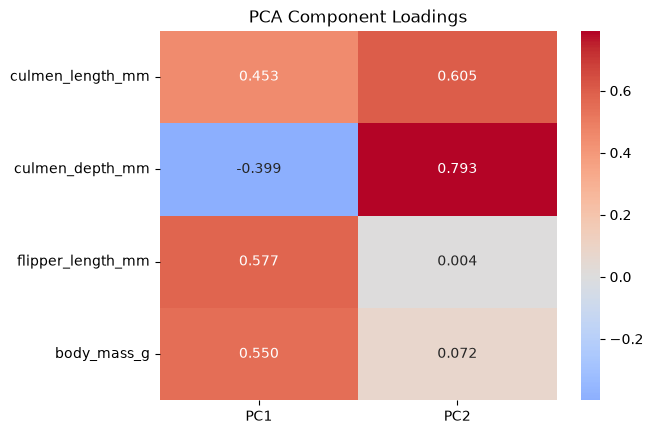

In [178]:
sns.heatmap(loadings, annot=True, cmap="coolwarm", center=0, fmt=".3f")
plt.title("PCA Component Loadings")
plt.show()

#### 19. Perform logistic regression (or any other classification algorithm) and evaluate the model

In [179]:
X_train, X_test, y_train, y_test = train_test_split(
    X_penguins_pca, y_penguins, test_size=0.3, random_state=42, stratify=y_penguins)

clf = LogisticRegression()
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.83
              precision    recall  f1-score   support

      FEMALE       0.84      0.82      0.83        50
        MALE       0.82      0.84      0.83        50

    accuracy                           0.83       100
   macro avg       0.83      0.83      0.83       100
weighted avg       0.83      0.83      0.83       100



#### 20. Train the model on all data points, and determine penguin sex for the data, where it was not originally identified

In [180]:
unknown = penguins[~penguins["sex"].isin(["MALE", "FEMALE"])]
unknown = unknown.dropna(subset=num_cols)
unknown = unknown[(unknown["flipper_length_mm"] > 0) & (unknown["flipper_length_mm"] < 300)]

X_unknown = scaler_p.transform(unknown[num_cols])

In [181]:
X_unknown_pca = pca.transform(X_unknown)

In [182]:
X_train = X_penguins_pca
y_train = y_penguins

clf_full = LogisticRegression()
clf_full.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [183]:
unknown = unknown.copy()
unknown["predicted_sex"] = clf_full.predict(X_unknown_pca)
unknown

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex,predicted_sex
8,34.1,18.1,193.0,3475.0,NaN,FEMALE
10,37.8,17.1,186.0,3300.0,NaN,FEMALE
11,37.8,17.3,180.0,3700.0,NaN,FEMALE
47,37.5,18.9,179.0,2975.0,NaN,FEMALE
246,44.5,14.3,216.0,4100.0,NaN,FEMALE
286,46.2,14.4,214.0,4650.0,NaN,FEMALE
324,47.3,13.8,216.0,4725.0,NaN,FEMALE
336,44.5,15.7,217.0,4875.0,.,FEMALE
